# Etapa 3: Modelado con XGBoost y Explicabilidad SHAP

**Objetivo:**
Entrenar el algoritmo definitivo (XGBoost) utilizando las variables temporales creadas en la Etapa 2. El desbalance extremo se manejará matemáticamente mediante `scale_pos_weight` en lugar de inyectar datos sintéticos.

**Explicabilidad (SHAP):**
En un entorno BPO, el operador necesita saber *por qué* se generó una alerta. SHAP desglosará el peso de cada variable en la decisión final.

In [6]:
import pandas as pd
import xgboost as xgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 1. Cargar el dataset enriquecido desde Parquet
df = pd.read_parquet('../data/features/temporal_features_v1.parquet')
print(f"Datos cargados: {df.shape[0]} filas, {df.shape[1]} columnas.")

Datos cargados: 284807 filas, 34 columnas.


In [7]:
# 2. Preparar los datos
# Eliminamos 'Time' porque ya extrajimos 'hour_of_day' y las medias móviles
X = df.drop(['Class', 'Time'], axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Calcular el ratio de desbalance para el parametro scale_pos_weight
ratio = float(y_train.value_counts()[0]) / y_train.value_counts()[1]
print(f"Ratio de desbalance (Legítimas / Fraudes): {ratio:.2f}")

Ratio de desbalance (Legítimas / Fraudes): 577.29


In [8]:
# 3. Entrenar XGBoost con peso penalizado
modelo_xgb = xgb.XGBClassifier(
    scale_pos_weight=ratio, 
    random_state=42, 
    n_jobs=-1,
    eval_metric='aucpr' # Area under the Precision-Recall curve
)

modelo_xgb.fit(X_train, y_train)

y_pred = modelo_xgb.predict(X_test)
print("\n[Reporte de Clasificación XGBoost]")
print(classification_report(y_test, y_pred, target_names=['Legítima', 'Fraude']))


[Reporte de Clasificación XGBoost]
              precision    recall  f1-score   support

    Legítima       1.00      1.00      1.00     56864
      Fraude       0.89      0.85      0.87        98

    accuracy                           1.00     56962
   macro avg       0.95      0.92      0.93     56962
weighted avg       1.00      1.00      1.00     56962



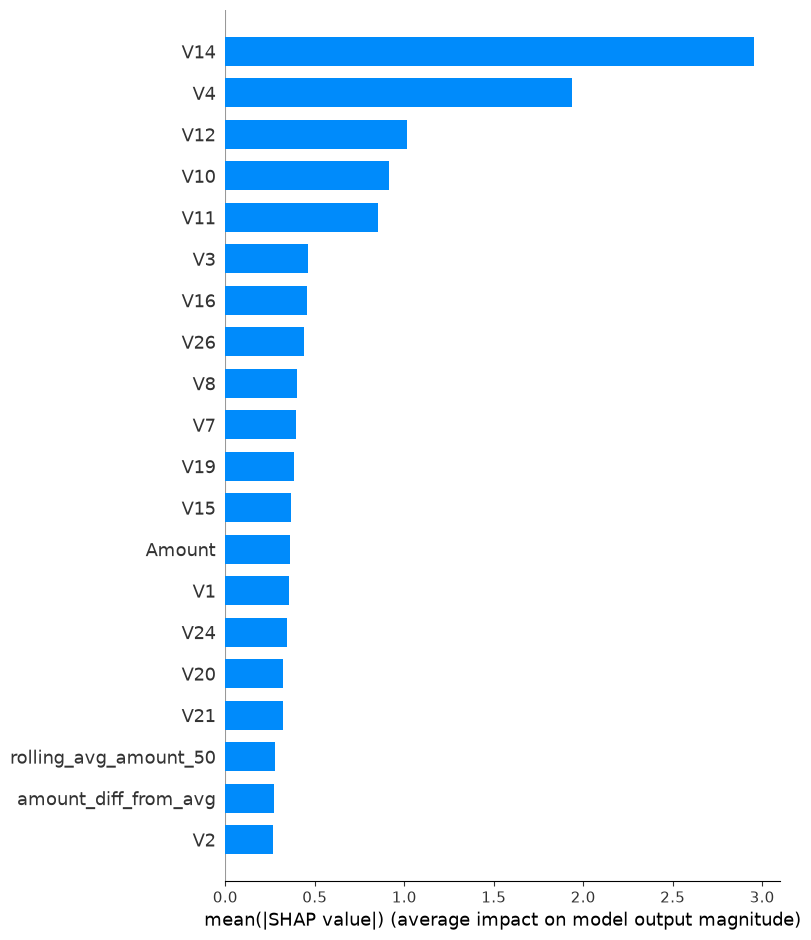

In [9]:
# 4. Explicabilidad con SHAP (Qué vio el modelo para tomar decisiones)
explainer = shap.TreeExplainer(modelo_xgb)
# Usamos una muestra para que no tarde demasiado en calcular
shap_values = explainer.shap_values(X_test.sample(1000, random_state=42))

shap.summary_plot(shap_values, X_test.sample(1000, random_state=42), plot_type="bar")